# EDA Dataset


## Sommaire

- **Partie 1 — Mise en place**
  - Imports, configuration, chargement du dataset brut
- **Partie 2 — Qualité globale du dataset**
  - [2. Structure du dataset brut](#2-structure-du-dataset-brut)
  - [3. Doublons](#3-doublons)
- **Partie 3 — Qualité des champs individuels**
  - [4. Qualité des champs textuels](#4-qualité-des-champs-textuels)
  - [5. Catégories issues des URLs](#5-catégories-issues-des-urls)
  - [6. Disponibilité](#6-disponibilité)
  - [7. Prix](#7-prix)
  - [8. Images et URLs](#8-images-et-urls)
- **Partie 4 — Ingrédients**
  - [9. Ingredients : couverture et qualité](#9-ingredients-couverture-et-qualité)
  - [10. Fallback pour les ingrédients](#10-fallback-pour-les-ingrédients)
- **Partie 5 — Normalisation et règles métier candidates**
  - [11. Normalisation textuelle](#11-normalisation-textuelle)
  - [12. Analyse des préoccupations (concerns)](#12-analyse-des-préoccupations-concerns)
  - [13. Déduction des étapes de routine](#13-déduction-des-étapes-de-routine)
  - [14. Détection des actifs](#14-détection-des-actifs)
  - [15. Détection des produits hors périmètre skincare visage](#15-détection-des-produits-hors-périmètre-skincare-visage)
- **Partie 6 — Synthèse, décisions et export**
  - [16. Colonnes finales nécessaires au système RenYou](#16-colonnes-finales-nécessaires-au-système-renyou)
  - [17. Génération d'un rapport EDA exportable](#17-génération-dun-rapport-eda-exportable)


# Partie 1 — Mise en place

Chargement du dataset brut et vérification de l'environnement d'exécution.

In [4]:
# ============================================================
# 1. IMPORTS ET CONFIGURATION
# ============================================================

from pathlib import Path
import re
import unicodedata
import ast
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

pd.set_option("display.max_columns", 100)
pd.set_option("display.max_colwidth", 120)

# ------------------------------------------------------------
# Chemin du projet dans Google Colab
# ------------------------------------------------------------

PROJECT_DIR = Path("/content")

# Dataset RAW directement présent dans /content
RAW_PATH = PROJECT_DIR / "parafendri_products_raw.csv"

print("Projet :", PROJECT_DIR)
print("Dataset :", RAW_PATH)

# Vérification
if not RAW_PATH.exists():
    raise FileNotFoundError(
        f"Dataset raw introuvable : {RAW_PATH}"
    )

# ------------------------------------------------------------
# Chargement du dataset
# ------------------------------------------------------------

df = pd.read_csv(RAW_PATH)

print(f"Nombre de lignes : {len(df):,}")
print(f"Nombre de colonnes : {len(df.columns)}")

display(df.head(5))

Projet : /content
Dataset : /content/parafendri_products_raw.csv
Nombre de lignes : 296
Nombre de colonnes : 11


,product_name,brand_name,price_tnd,availability,short_description,product_url,category_url,detail_description,ingredients,image_url,detail_brand_name
0,XEN ACNOZ GEL NETTOYANT 300 ML,xen,30.0,in_stock,"949 Ac-noz Gel nettoyant, gel moussant, sans savon, pour l'hygiène des peaux grasses et / ou à tendance acnéiques",https://parafendri.tn/visage/28-xen-acnoz-gel-nettoyant-300-ml-visage-xen.html,https://parafendri.tn/18-peaux-grasses,"Ac-noz Gel nettoyant, gel moussant, sans savon, pour l'hygiène des peaux grasses et / ou à tendance acnéiques Ac-noz...",NaN,https://parafendri.tn/24-large_default/xen-acnoz-gel-nettoyant-300-ml-visage-xen.webp,NaN
1,CAUDALIE VINOPURE - MOUSSE MICRO PEELING ECLAT 100ML,Caudalie,85.0,in_stock,"993 Type de peau : Tous types de peau Besoin : Eclat, Anti-taches Texture : Mousse Ingrédients clés : Eau de Raisin ...",https://parafendri.tn/soins/10349-caudalie-vinopure-mousse-micro-peeling-eclat-100ml.html,https://parafendri.tn/18-peaux-grasses,"Type de peau : Tous types de peau Besoin : Eclat, Anti-taches Texture : Mousse Ingrédients clés : Eau de Raisin bio,...","Ingrédients clés : Eau de Raisin bio, AHAs, Acide Mandélique 85,000 TND TTC Quantité  Ajouter au panier Ajouter à l...",https://parafendri.tn/9670-large_default/caudalie-vinopure-mousse-micro-peeling-eclat-100ml.webp,NaN
2,DUCRAY KERACNYL PP+ CREME ANTI IMPERFECTIONS 30ML,DUCRAY,48.0,in_stock,883 Keracnyl PP+ 30 ml est un soin anti-imperfections spécialement formulé pour les peaux à tendance acnéique. Il ai...,https://parafendri.tn/beaute/701-ducray-keracnyl-ppcreme-apaisante-anti-imperfections-30ml-beaute-ducray.html,https://parafendri.tn/18-peaux-grasses,DUCRAY Keracnyl PP+ 30 ml est un soin anti-imperfections spécialement formulé pour les peaux à tendance acnéique. Il...,"ingrédients naturels. Add to Compare BIO ORIENT Bio Orient Huile De Sésame, 10ml 4,000 TND Ajouter au panier Disponi...",https://parafendri.tn/10823-large_default/ducray-keracnyl-ppcreme-apaisante-anti-imperfections-30ml-beaute-ducray.webp,NaN
3,DUCRAY KERACNYL GEL MOUSSANT 200ML,DUCRAY,40.0,in_stock,"866 Ducray Keracnyl Gel Moussant 200 ml est un nettoyant sans savon enrichi en Myrtacine. Il nettoie en douceur, pur...",https://parafendri.tn/beaute/714-ducray-keracnyl-gel-moussant-200ml-beaute-ducray.html,https://parafendri.tn/18-peaux-grasses,"Ducray Keracnyl Gel Moussant 200 ml est un nettoyant sans savon enrichi en Myrtacine. Il nettoie en douceur, purifie...","Composition: Aqua (Water), Zinc Coceth Sulfate, Lauryl Betaine, Decyl Glucoside, Ceteareth-60 Myristyl Glycol, Polys...",https://parafendri.tn/9070-large_default/ducray-keracnyl-gel-moussant-200ml-beaute-ducray.webp,NaN
4,AVENE FLUIDE SPF 50+ PEAU SENSIBLE NORMALES A MIXTES 50ML,AVENE,42.0,out_of_stock,"En rupture de stock Solaire Très haute protection SPF50+ Fluide Résiste à l'eau, toucher sec Visage et cou Peaux Sen...",https://parafendri.tn/beaute/721-avene-fluide-spf-50-peau-sensible-normales-a-mixtes-50ml-beaute-avene.html,https://parafendri.tn/18-peaux-grasses,"AVENE Solaire Très haute protection SPF50+ Fluide Résiste à l'eau, toucher sec Visage et cou Peaux Sensibles Normale...",NaN,https://parafendri.tn/5997-large_default/avene-fluide-spf-50-peau-sensible-normales-a-mixtes-50ml-beaute-avene.webp,NaN


In [5]:
if not RAW_PATH.exists():
    raise FileNotFoundError(
        f"Dataset raw introuvable : {RAW_PATH}\n"
        "Placez le notebook dans le projet ou modifiez RAW_PATH."
    )

df = pd.read_csv(RAW_PATH)

print(f"Nombre de lignes : {len(df):,}")
print(f"Nombre de colonnes : {len(df.columns)}")
display(df.head(5))


Nombre de lignes : 296
Nombre de colonnes : 11


,product_name,brand_name,price_tnd,availability,short_description,product_url,category_url,detail_description,ingredients,image_url,detail_brand_name
0,XEN ACNOZ GEL NETTOYANT 300 ML,xen,30.0,in_stock,"949 Ac-noz Gel nettoyant, gel moussant, sans savon, pour l'hygiène des peaux grasses et / ou à tendance acnéiques",https://parafendri.tn/visage/28-xen-acnoz-gel-nettoyant-300-ml-visage-xen.html,https://parafendri.tn/18-peaux-grasses,"Ac-noz Gel nettoyant, gel moussant, sans savon, pour l'hygiène des peaux grasses et / ou à tendance acnéiques Ac-noz...",NaN,https://parafendri.tn/24-large_default/xen-acnoz-gel-nettoyant-300-ml-visage-xen.webp,NaN
1,CAUDALIE VINOPURE - MOUSSE MICRO PEELING ECLAT 100ML,Caudalie,85.0,in_stock,"993 Type de peau : Tous types de peau Besoin : Eclat, Anti-taches Texture : Mousse Ingrédients clés : Eau de Raisin ...",https://parafendri.tn/soins/10349-caudalie-vinopure-mousse-micro-peeling-eclat-100ml.html,https://parafendri.tn/18-peaux-grasses,"Type de peau : Tous types de peau Besoin : Eclat, Anti-taches Texture : Mousse Ingrédients clés : Eau de Raisin bio,...","Ingrédients clés : Eau de Raisin bio, AHAs, Acide Mandélique 85,000 TND TTC Quantité  Ajouter au panier Ajouter à l...",https://parafendri.tn/9670-large_default/caudalie-vinopure-mousse-micro-peeling-eclat-100ml.webp,NaN
2,DUCRAY KERACNYL PP+ CREME ANTI IMPERFECTIONS 30ML,DUCRAY,48.0,in_stock,883 Keracnyl PP+ 30 ml est un soin anti-imperfections spécialement formulé pour les peaux à tendance acnéique. Il ai...,https://parafendri.tn/beaute/701-ducray-keracnyl-ppcreme-apaisante-anti-imperfections-30ml-beaute-ducray.html,https://parafendri.tn/18-peaux-grasses,DUCRAY Keracnyl PP+ 30 ml est un soin anti-imperfections spécialement formulé pour les peaux à tendance acnéique. Il...,"ingrédients naturels. Add to Compare BIO ORIENT Bio Orient Huile De Sésame, 10ml 4,000 TND Ajouter au panier Disponi...",https://parafendri.tn/10823-large_default/ducray-keracnyl-ppcreme-apaisante-anti-imperfections-30ml-beaute-ducray.webp,NaN
3,DUCRAY KERACNYL GEL MOUSSANT 200ML,DUCRAY,40.0,in_stock,"866 Ducray Keracnyl Gel Moussant 200 ml est un nettoyant sans savon enrichi en Myrtacine. Il nettoie en douceur, pur...",https://parafendri.tn/beaute/714-ducray-keracnyl-gel-moussant-200ml-beaute-ducray.html,https://parafendri.tn/18-peaux-grasses,"Ducray Keracnyl Gel Moussant 200 ml est un nettoyant sans savon enrichi en Myrtacine. Il nettoie en douceur, purifie...","Composition: Aqua (Water), Zinc Coceth Sulfate, Lauryl Betaine, Decyl Glucoside, Ceteareth-60 Myristyl Glycol, Polys...",https://parafendri.tn/9070-large_default/ducray-keracnyl-gel-moussant-200ml-beaute-ducray.webp,NaN
4,AVENE FLUIDE SPF 50+ PEAU SENSIBLE NORMALES A MIXTES 50ML,AVENE,42.0,out_of_stock,"En rupture de stock Solaire Très haute protection SPF50+ Fluide Résiste à l'eau, toucher sec Visage et cou Peaux Sen...",https://parafendri.tn/beaute/721-avene-fluide-spf-50-peau-sensible-normales-a-mixtes-50ml-beaute-avene.html,https://parafendri.tn/18-peaux-grasses,"AVENE Solaire Très haute protection SPF50+ Fluide Résiste à l'eau, toucher sec Visage et cou Peaux Sensibles Normale...",NaN,https://parafendri.tn/5997-large_default/avene-fluide-spf-50-peau-sensible-normales-a-mixtes-50ml-beaute-avene.webp,NaN


# Partie 2 — Qualité globale du dataset

Structure, types, valeurs manquantes et doublons, **avant toute correction**.

## 2. Structure du dataset brut

On commence par vérifier ce que le scraping a réellement produit.  

In [6]:
# Colonnes, types et mémoire
display(pd.DataFrame({
    "column": df.columns,
    "dtype": [df[c].dtype for c in df.columns],
    "non_null": [df[c].notna().sum() for c in df.columns],
    "missing": [df[c].isna().sum() for c in df.columns],
    "missing_%": [round(df[c].isna().mean()*100, 2) for c in df.columns],
    "n_unique": [df[c].nunique(dropna=True) for c in df.columns],
}))

print("\nTypes pandas :")
display(df.dtypes)


,column,dtype,non_null,missing,missing_%,n_unique
0,product_name,object,296,0,0.00,296
1,brand_name,object,271,25,8.45,66
2,price_tnd,float64,296,0,0.00,108
3,availability,object,296,0,0.00,2
4,short_description,object,296,0,0.00,268
5,product_url,object,296,0,0.00,296
6,category_url,object,296,0,0.00,12
7,detail_description,object,296,0,0.00,296
8,ingredients,object,158,138,46.62,158
9,image_url,object,296,0,0.00,296



Types pandas :


,0
product_name,object
brand_name,object
price_tnd,float64
availability,object
short_description,object
product_url,object
category_url,object
detail_description,object
ingredients,object
image_url,object


In [7]:
# Valeurs vides sous différentes formes
EMPTY_VALUES = {"", " ", "nan", "none", "null", "n/a", "na", "-"}

def empty_like_count(s):
    return s.astype(str).str.strip().str.lower().isin(EMPTY_VALUES).sum()

empty_report = pd.DataFrame({
    "column": df.columns,
    "NaN": [df[c].isna().sum() for c in df.columns],
    "empty_like": [empty_like_count(df[c]) for c in df.columns],
})
empty_report["total_missing_or_empty"] = empty_report["NaN"] + empty_report["empty_like"]
empty_report["rate_%"] = (empty_report["total_missing_or_empty"] / len(df) * 100).round(2)

display(empty_report.sort_values("rate_%", ascending=False))


,column,NaN,empty_like,total_missing_or_empty,rate_%
10,detail_brand_name,296,296,592,200.00
8,ingredients,138,138,276,93.24
1,brand_name,25,25,50,16.89
2,price_tnd,0,0,0,0.00
0,product_name,0,0,0,0.00
3,availability,0,0,0,0.00
4,short_description,0,0,0,0.00
6,category_url,0,0,0,0.00
5,product_url,0,0,0,0.00
7,detail_description,0,0,0,0.00


### Décision à prendre

Pour chaque colonne, le taux de valeurs manquantes permet de décider :

- conserver la colonne telle quelle ;
- nettoyer les valeurs vides ;
- reconstruire la colonne à partir d'une autre source ;
- supprimer la colonne si elle n'apporte aucune valeur au futur système.

**On ne supprime pas une colonne uniquement parce qu'elle contient des valeurs manquantes.** On regarde d'abord son utilité pour la recommandation.


## 3. Doublons

Le scraper effectue déjà un `drop_duplicates` sur `product_url + product_name` pendant la collecte.

L'EDA vérifie néanmoins s'il reste :

- des doublons exacts ;
- plusieurs lignes pour le même produit ;
- des noms identiques avec des URLs différentes.


In [8]:
print("Doublons de lignes complètes :", df.duplicated().sum())
print("Doublons product_name :", df["product_name"].duplicated(keep=False).sum())
print("Doublons product_url :", df["product_url"].duplicated(keep=False).sum())

dup_names = (
    df[df["product_name"].duplicated(keep=False)]
    .sort_values("product_name")
)

display(dup_names[["product_name", "brand_name", "product_url", "category_url"]].head(50))


Doublons de lignes complètes : 0
Doublons product_name : 0
Doublons product_url : 0


,product_name,brand_name,product_url,category_url


In [9]:
# Même produit probable : même nom + même marque
key_cols = [c for c in ["product_name", "brand_name"] if c in df.columns]
if key_cols:
    duplicated_business_key = df[df.duplicated(key_cols, keep=False)].sort_values(key_cols)
    print(f"Doublons sur {key_cols} :", len(duplicated_business_key))
    display(duplicated_business_key[key_cols + ["product_url", "category_url"]].head(50))


Doublons sur ['product_name', 'brand_name'] : 0


,product_name,brand_name,product_url,category_url


# Partie 3 — Qualité des champs individuels

Analyse champ par champ : textes, catégories, disponibilité, prix, images.

## 4. Qualité des champs textuels

On mesure :

- longueur des noms
- longueur des descriptions
- longueur des ingrédients
- textes identiques ou quasi-identiques
- présence de bruit de scraping.


In [10]:
TEXT_COLS = [
    c for c in [
        "product_name", "brand_name", "short_description",
        "detail_description", "ingredients"
    ] if c in df.columns
]

for col in TEXT_COLS:
    s = df[col].fillna("").astype(str)
    lengths = s.str.len()
    print(f"\n### {col}")
    print("vide :", (s.str.strip() == "").sum())
    print("min  :", lengths.min())
    print("median :", lengths.median())
    print("max  :", lengths.max())
    display(lengths.describe(percentiles=[.25, .5, .75, .9, .95, .99]).to_frame("length"))



### product_name
vide : 0
min  : 21
median : 47.5
max  : 120


,length
count,296.000000
mean,50.273649
std,15.156230
min,21.000000
25%,40.000000
50%,47.500000
75%,58.000000
90%,71.000000
95%,76.500000
99%,93.000000



### brand_name
vide : 25
min  : 0
median : 6.0
max  : 20


,length
count,296.000000
mean,6.256757
std,3.217793
min,0.000000
25%,5.000000
50%,6.000000
75%,8.000000
90%,11.000000
95%,11.000000
99%,14.000000



### short_description
vide : 0
min  : 2
median : 145.0
max  : 592


,length
count,296.000000
mean,146.270270
std,120.237539
min,2.000000
25%,19.000000
50%,145.000000
75%,222.750000
90%,289.500000
95%,348.000000
99%,503.600000



### detail_description
vide : 0
min  : 703
median : 2888.0
max  : 11782


,length
count,296.000000
mean,3296.172297
std,1860.868689
min,703.000000
25%,2025.000000
50%,2888.000000
75%,4074.750000
90%,5969.000000
95%,6863.000000
99%,9297.650000



### ingredients
vide : 138
min  : 0
median : 257.5
max  : 2000


,length
count,296.000000
mean,468.864865
std,562.378673
min,0.000000
25%,0.000000
50%,257.500000
75%,851.250000
90%,1263.500000
95%,1588.250000
99%,2000.000000


In [11]:
# Exemples de descriptions contenant du bruit connu du scraping
NOISE_PATTERNS = [
    r"ajouter au panier",
    r"add to compare",
    r"disponibilit",
    r"en stock",
    r"rupture de stock",
    r"référence\s*:",
    r"reference\s*:",
    r"\b\d+[,.]?\d*\s*TND\b",
]

for pattern in NOISE_PATTERNS:
    mask = (
        df.get("short_description", pd.Series("", index=df.index))
        .fillna("").astype(str).str.contains(pattern, case=False, regex=True)
    )
    print(f"{pattern:30s} -> {mask.sum():4d} lignes")
    if mask.sum():
        display(df.loc[mask, ["product_name", "short_description"]].head(3))


ajouter au panier              ->    0 lignes
add to compare                 ->    0 lignes
disponibilit                   ->    0 lignes
en stock                       ->    0 lignes
rupture de stock               ->   33 lignes


,product_name,short_description
4,AVENE FLUIDE SPF 50+ PEAU SENSIBLE NORMALES A MIXTES 50ML,"En rupture de stock Solaire Très haute protection SPF50+ Fluide Résiste à l'eau, toucher sec Visage et cou Peaux Sen..."
5,AVENE FLUIDE MINÉRAL TEINTÉ SPF50+ 40ML,En rupture de stock 0donne un éclat translucide et ensoleillé
28,CYTOLNAT - PACK : ECRAN SOLAIRE INVISIBLE SPG50+ +GEL NETTOYANT PEAUX MIXTES A GRASSES + CREME HYDRATANTE VISAGE OFF...,- Désactivé En rupture de stock


référence\s*:                  ->    0 lignes
reference\s*:                  ->    0 lignes
\b\d+[,.]?\d*\s*TND\b          ->    0 lignes


### Ce que cette analyse doit permettre de conclure

Si les mêmes fragments apparaissent systématiquement dans `short_description`, ils constituent des **artefacts de scraping** et peuvent être retirés



## 5. Catégories issues des URLs

Le scraper collecte `category_url`, pas une catégorie métier normalisée.

On inspecte donc les slugs réellement présents avant de décider comment construire `category`.


In [12]:
def category_slug(url):
    if pd.isna(url):
        return ""
    url = str(url).strip()
    if not url:
        return ""
    slug = url.rstrip("/").split("/")[-1].lower()
    slug = re.sub(r"^\d+-", "", slug)
    return slug.replace("_", "-")

df["category_slug_eda"] = df["category_url"].apply(category_slug)

category_stats = (
    df["category_slug_eda"]
    .value_counts(dropna=False)
    .rename_axis("category_slug")
    .reset_index(name="n_products")
)

category_stats["share_%"] = (category_stats["n_products"] / len(df) * 100).round(2)
display(category_stats)


,category_slug,n_products,share_%
0,peaux-grasses,43,14.53
1,anti-taches-et-depigmentants,37,12.50
2,peaux-seches,35,11.82
3,nettoyants-et-demaquillants,34,11.49
4,peaux-sensibles-,31,10.47
5,peeling-du-visage,24,8.11
6,apres-solaire,23,7.77
7,apaisants,21,7.09
8,peaux-acneiques,19,6.42
9,creme-solaire-,18,6.08


### Recherche des catégories exploitables pour `skin_type`

On ne doit pas déduire un type de peau lorsque la catégorie ne le garantit pas.

Par exemple, une catégorie explicitement appelée « peaux grasses » fournit une information exploitable ; une catégorie « anti-taches » ne donne pas nécessairement le type de peau.

Le tableau suivant permet de décider quelles catégories peuvent alimenter `skin_type`.


In [13]:
SKIN_CATEGORY_CANDIDATES = [
    "grasse", "seche", "mixte", "sensible", "acneique", "normale", "mature", "atopique"
]

for slug in category_stats["category_slug"]:
    if any(token in slug for token in SKIN_CATEGORY_CANDIDATES):
        print(slug, "-> candidat skin_type")


peaux-grasses -> candidat skin_type
peaux-seches -> candidat skin_type
peaux-sensibles- -> candidat skin_type
peaux-acneiques -> candidat skin_type
peaux-mixtes -> candidat skin_type


## 6. Disponibilité

Le scraper transforme déjà les informations visibles en trois états : `in_stock`, `out_of_stock` et `unknown`.

L'EDA vérifie la distribution réelle et les éventuelles valeurs inattendues.


In [14]:
if "availability" in df:
    display(df["availability"].fillna("<NA>").value_counts(dropna=False))
    unknown = df["availability"].fillna("").astype(str).str.strip().str.lower().eq("unknown")
    print("unknown :", unknown.sum(), f"({unknown.mean()*100:.2f}%)")


,count
availability,
in_stock,263
out_of_stock,33


unknown : 0 (0.00%)


## 7. Prix

Le scraper extrait un prix numérique `price_tnd` à partir du texte TND.

On vérifie ici les valeurs aberrantes et les prix manquants avant de décider s'il faut conserver ce champ pour l'application.


,price_tnd
count,296.000000
mean,60.327365
std,32.820265
min,10.000000
1%,11.900000
5%,19.000000
25%,38.000000
50%,52.000000
75%,75.000000
95%,127.000000


Prix manquants : 0
Prix <= 0 : 0


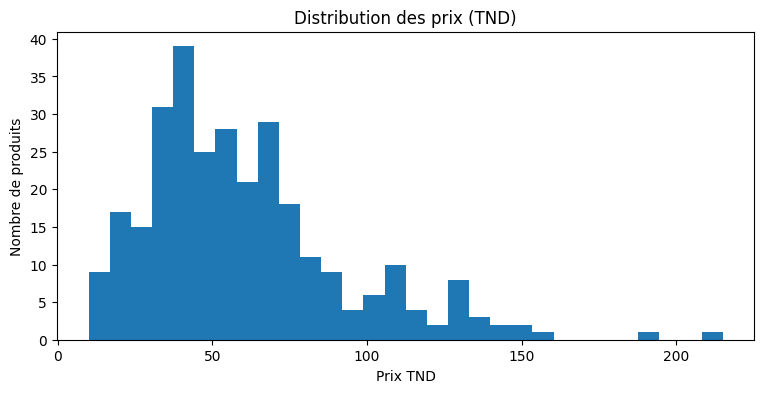

In [15]:
if "price_tnd" in df:
    price = pd.to_numeric(df["price_tnd"], errors="coerce")
    display(price.describe(percentiles=[.01, .05, .25, .5, .75, .95, .99]).to_frame("price_tnd"))
    print("Prix manquants :", price.isna().sum())
    print("Prix <= 0 :", (price <= 0).sum())

    plt.figure(figsize=(9, 4))
    price.dropna().plot(kind="hist", bins=30)
    plt.title("Distribution des prix (TND)")
    plt.xlabel("Prix TND")
    plt.ylabel("Nombre de produits")
    plt.show()


## 8. Images et URLs

Le scraper filtre déjà plusieurs placeholders (`loader`, `spinner`, `placeholder`, `logo`, etc.) lors de l'extraction d'image.

L'EDA vérifie néanmoins le résultat final.


In [16]:
for col in ["product_url", "image_url"]:
    if col in df:
        s = df[col].fillna("").astype(str).str.strip()
        print(f"{col}:")
        print("  vide :", (s == "").sum())
        print("  unique :", s.nunique())
        if col == "image_url":
            bad_patterns = ["loader", "spinner", "placeholder", "logo", "icon", "blank"]
            for p in bad_patterns:
                print(f"  contient '{p}' :", s.str.contains(p, case=False, regex=False).sum())


product_url:
  vide : 0
  unique : 296
image_url:
  vide : 0
  unique : 296
  contient 'loader' : 0
  contient 'spinner' : 0
  contient 'placeholder' : 0
  contient 'logo' : 0
  contient 'icon' : 0
  contient 'blank' : 0


# Partie 4 — Ingrédients

Couverture, qualité et stratégie de fallback pour le champ `ingredients`, central pour la recommandation.

## 9. Ingredients : couverture et qualité

Les ingrédients sont particulièrement importants pour RenYou car ils serviront ensuite à détecter les actifs et à alimenter la recommandation.

Le scraper utilise une extraction heuristique depuis le texte de la page et limite le résultat à 2000 caractères.

On mesure donc :

- combien de produits ont une information ingrédients ;
- longueur des blocs ;
- formulations utilisées (`Composition`, `INCI`, `Ingrédients`, etc.) ;
- cas suspects.


In [17]:
if "ingredients" in df:
    ing = df["ingredients"].fillna("").astype(str).str.strip()
    print("Produits avec ingrédients :", (ing != "").sum(), f"/ {len(df)}")
    print("Couverture :", round((ing != "").mean()*100, 2), "%")
    display(ing.str.len().describe(percentiles=[.5, .75, .9, .95, .99]).to_frame("ingredients_length"))

    print("\nMots-clés de structure détectés :")
    for kw in ["composition", "inci", "ingrédients", "ingredients"]:
        n = ing.str.contains(kw, case=False, regex=False).sum()
        print(f"{kw:15s}: {n}")


Produits avec ingrédients : 158 / 296
Couverture : 53.38 %


,ingredients_length
count,296.000000
mean,468.864865
std,562.378673
min,0.000000
50%,257.500000
75%,851.250000
90%,1263.500000
95%,1588.250000
99%,2000.000000
max,2000.000000



Mots-clés de structure détectés :
composition    : 70
inci           : 55
ingrédients    : 58
ingredients    : 0


## 10. Fallback pour les ingrédients

On vérifie si `detail_description` ou `short_description` contient des sections d'ingrédients lorsque la colonne `ingredients` est vide.



In [18]:
def extract_ingredient_section(text):
    if pd.isna(text):
        return ""
    text = str(text)
    patterns = [
        r"(?is)liste\s+complete\s+d['’]ingredients?\s*:?\s*(.*)",
        r"(?is)liste\s+complete\s+des\s+ingredients?\s*:?\s*(.*)",
        r"(?is)full\s+ingredients?\s*:?\s*(.*)",
        r"(?is)composition\s*\(?\s*inci\s*\)?\s*:?\s*(.*)",
        r"(?is)composition\s*:?\s*(.*)",
        r"(?is)ingredients?\s*\(?\s*inci\s*\)?\s*:?\s*(.*)",
        r"(?is)ingr[eé]dients?\s*:?\s*(.*)",
    ]
    for p in patterns:
        m = re.search(p, text)
        if m:
            result = re.split(
                r"(?i)\b(?:conseils?|mode d'emploi|utilisation|"
                r"precautions?|avantages?|proprietes?|description|benefices?)\b",
                m.group(1)
            )[0]
            result = re.sub(r"\s+", " ", result).strip()
            if result:
                return result
    return ""

if "ingredients" in df:
    ing_empty = df["ingredients"].fillna("").astype(str).str.strip().eq("")
    detail = df.get("detail_description", pd.Series("", index=df.index)).fillna("")
    short = df.get("short_description", pd.Series("", index=df.index)).fillna("")

    fallback_detail = detail.apply(extract_ingredient_section)
    fallback_short = short.apply(extract_ingredient_section)

    print("Ingredients vides :", ing_empty.sum())
    print("Récupérables depuis detail_description :", (ing_empty & fallback_detail.ne("")).sum())
    print("Récupérables depuis short_description :", (ing_empty & fallback_short.ne("")).sum())

    display(pd.DataFrame({
        "product_name": df["product_name"],
        "raw_ingredients": df["ingredients"],
        "detail_candidate": fallback_detail,
        "short_candidate": fallback_short
    })[ing_empty & (fallback_detail.ne("") | fallback_short.ne(""))].head(20))


Ingredients vides : 138
Récupérables depuis detail_description : 3
Récupérables depuis short_description : 0


,product_name,raw_ingredients,detail_candidate,short_candidate
150,EUCERIN ANTI-PIGMENT Soin de Jour SPF30,NaN,efficace et breveté qui agit à la base de l'hyperpigmentation en réduisant la production de mélanine. Il est prouvé ...,
151,EUCERIN ANTI-PIGMENT Soin de Nuit,NaN,efficace et breveté qui agit à la base de l'hyperpigmentation en réduisant la production de mélanine. Il est cliniqu...,
194,CLARENIA GB5 SÉRUM PEELING EXFOLIANT 30ML,NaN,apaisant pour la peau en raison de ses propriétés anti-inflammatoires et hydratantes. Le Clarenia GB5 Sérum Peeling ...,


# Partie 5 — Normalisation et règles métier candidates

Vue normalisée temporaire, puis exploration des préoccupations, étapes de routine, actifs et produits hors périmètre — pour justifier chaque règle avant de l'écrire dans `clean_dataset.py`.

## 11. Normalisation textuelle

Avant de définir les règles métier, on crée une **vue normalisée temporaire uniquement pour l'EDA** :

- minuscules ;
- accents supprimés ;
- espaces normalisés.

Cela permet de voir que `Acné`, `acnéique` et `ACNE` peuvent appartenir au même groupe de recherche, sans modifier le raw.


In [19]:
def normalize_eda(text):
    if pd.isna(text):
        return ""
    text = str(text).lower().strip()
    text = unicodedata.normalize("NFD", text)
    text = "".join(c for c in text if unicodedata.category(c) != "Mn")
    text = re.sub(r"\s+", " ", text)
    return text

df["product_name_norm_eda"] = df["product_name"].apply(normalize_eda)
df["description_norm_eda"] = (
    df.get("short_description", pd.Series("", index=df.index)).fillna("").apply(normalize_eda)
    + " "
    + df.get("detail_description", pd.Series("", index=df.index)).fillna("").apply(normalize_eda)
)

display(df[["product_name", "product_name_norm_eda"]].head(20))


,product_name,product_name_norm_eda
0,XEN ACNOZ GEL NETTOYANT 300 ML,xen acnoz gel nettoyant 300 ml
1,CAUDALIE VINOPURE - MOUSSE MICRO PEELING ECLAT 100ML,caudalie vinopure - mousse micro peeling eclat 100ml
2,DUCRAY KERACNYL PP+ CREME ANTI IMPERFECTIONS 30ML,ducray keracnyl pp+ creme anti imperfections 30ml
3,DUCRAY KERACNYL GEL MOUSSANT 200ML,ducray keracnyl gel moussant 200ml
4,AVENE FLUIDE SPF 50+ PEAU SENSIBLE NORMALES A MIXTES 50ML,avene fluide spf 50+ peau sensible normales a mixtes 50ml
5,AVENE FLUIDE MINÉRAL TEINTÉ SPF50+ 40ML,avene fluide mineral teinte spf50+ 40ml
6,SVR SUN SECURE EXTREME SPF50+ 50ML,svr sun secure extreme spf50+ 50ml
7,BIODERMA sebium eau micellaire purifiante 500ml peaux mixtes a grasses,bioderma sebium eau micellaire purifiante 500ml peaux mixtes a grasses
8,bioderma sebium gel moussant purifiant 200ml pompe peaux mixtes a grasses,bioderma sebium gel moussant purifiant 200ml pompe peaux mixtes a grasses
9,EUCERIN DERMOPURE - GOMMAGE PEAUX A IMPERFECTIONS 100ML,eucerin dermopure - gommage peaux a imperfections 100ml


## 12. Analyse des préoccupations (concerns)

On cherche les termes réellement présents dans le catalogue avant de créer les règles.

Les familles étudiées sont :

- acné / imperfections ;
- taches / pigmentation ;
- déshydratation / hydratation ;
- sécheresse ;
- rougeurs / apaisement ;
- rides / anti-âge ;
- pores ;
- sensibilité.

Le notebook affiche les occurrences afin que les mots retenus dans `clean_dataset.py` soient justifiés par les données.


In [20]:
CONCERN_CANDIDATES = {
    "acne": ["acne", "acneique", "imperfections", "boutons", "points noirs", "comedons", "anti-imperfections"],
    "taches": ["taches", "tache", "pigmentation", "depigmentant", "depigmentation", "eclaircissant", "eclat", "teint"],
    "deshydratation": ["deshydratation", "deshydrate", "hydratation", "repulpant", "hydratant"],
    "secheresse": ["peau seche", "peaux seches", "secheresse"],
    "rougeurs": ["rougeurs", "rougeur", "rosacee", "couperose", "apaise", "apaisant"],
    "rides": ["rides", "ridules", "anti-age", "antirides", "fermete"],
    "pores": ["pores", "pores dilates"],
    "sensibilite": ["peau sensible", "peaux sensibles", "sensible"],
}

concern_text = (
    df["product_name_norm_eda"].fillna("")
    + " " + df["description_norm_eda"].fillna("")
    + " " + df["category_slug_eda"].fillna("")
)

concern_report = []
for concern, keywords in CONCERN_CANDIDATES.items():
    row = {"concern": concern}
    total = pd.Series(False, index=df.index)
    for kw in keywords:
        mask = concern_text.str.contains(re.escape(normalize_eda(kw)), regex=True)
        row[kw] = int(mask.sum())
        total |= mask
    row["products_matching_family"] = int(total.sum())
    concern_report.append(row)

concern_report = pd.DataFrame(concern_report)
display(concern_report.sort_values("products_matching_family", ascending=False))


,concern,acne,acneique,imperfections,boutons,points noirs,comedons,anti-imperfections,products_matching_family,taches,tache,pigmentation,depigmentant,depigmentation,eclaircissant,eclat,teint,deshydratation,deshydrate,hydratation,repulpant,hydratant,peau seche,peaux seches,secheresse,rougeurs,rougeur,rosacee,couperose,apaise,apaisant,rides,ridules,anti-age,antirides,fermete,pores,pores dilates,peau sensible,peaux sensibles,sensible
1,taches,NaN,NaN,NaN,NaN,NaN,NaN,NaN,255,120.0,125.0,40.0,46.0,0.0,49.0,130.0,201.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
7,sensibilite,NaN,NaN,NaN,NaN,NaN,NaN,NaN,198,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,20.0,137.0,198.0
4,rougeurs,NaN,NaN,NaN,NaN,NaN,NaN,NaN,194,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,58.0,60.0,3.0,3.0,137.0,121.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,deshydratation,NaN,NaN,NaN,NaN,NaN,NaN,NaN,194,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,9.0,13.0,88.0,12.0,166.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
0,acne,83.0,64.0,128.0,35.0,23.0,1.0,26.0,155,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
5,rides,NaN,NaN,NaN,NaN,NaN,NaN,NaN,116,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,81.0,31.0,55.0,1.0,20.0,NaN,NaN,NaN,NaN,NaN
3,secheresse,NaN,NaN,NaN,NaN,NaN,NaN,NaN,80,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,23.0,56.0,19.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
6,pores,NaN,NaN,NaN,NaN,NaN,NaN,NaN,66,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,66.0,12.0,NaN,NaN,NaN


### Vérification des faux positifs

Une simple recherche par sous-chaîne peut créer des collisions.  
On teste donc les mots courts et ambigus avant de les intégrer dans les règles.

Exemples de principe :

- éviter de considérer `uv` comme un mot autonome s'il apparaît à l'intérieur d'un autre mot ;
- éviter de considérer `pha` comme un actif simplement parce qu'il apparaît dans un nom de marque.

Cette étape justifie l'utilisation éventuelle de frontières regex dans `clean_dataset.py`.


In [21]:
# Test de collision : quelques tokens courts potentiellement dangereux
SHORT_TOKENS = ["uv", "pha", "bha", "aha", "cica", "zinc"]

for token in SHORT_TOKENS:
    loose = concern_text.str.contains(re.escape(token), regex=True).sum()
    bounded = concern_text.str.contains(
        rf"(?<![a-z]){re.escape(token)}(?![a-z0-9])",
        regex=True
    ).sum()
    print(f"{token:6s} | recherche simple = {loose:4d} | recherche bornée = {bounded:4d}")


uv     | recherche simple =  188 | recherche bornée =   64
pha    | recherche simple =   92 | recherche bornée =    3
bha    | recherche simple =    6 | recherche bornée =    6
aha    | recherche simple =   11 | recherche bornée =   11
cica   | recherche simple =   40 | recherche bornée =   13
zinc   | recherche simple =   20 | recherche bornée =   20


## 13. Déduction des étapes de routine

Cette partie est essentielle pour RenYou.

On analyse **le nom du produit** et les termes rencontrés dans le catalogue afin de déterminer si une règle peut identifier :

- démaquillage ;
- nettoyage ;
- sérum ;
- traitement ;
- hydratant ;
- protection solaire ;
- réparation.

L'objectif de l'EDA est de voir les formulations réelles du catalogue **avant** d'écrire les règles.


In [22]:
ROUTINE_TERMS = [
    "demaquillant", "eau micellaire", "nettoyant", "gel nettoyant",
    "mousse nettoyante", "mousse lavante", "lotion nettoyante",
    "huile lavante", "savon", "gel lavant",
    "serum", "ampoule", "concentre",
    "anti-acne", "anti-imperfections", "correcteur", "traitement",
    "peeling", "exfoliant", "gommage", "masque",
    "creme hydratante", "gel creme", "soin hydratant", "lait hydratant",
    "reparateur", "baume reparateur", "cica", "barriere cutanee",
    "spf", "ecran solaire", "creme solaire", "protection solaire",
    "sun secure", "uv", "apres soleil", "apres-soleil", "after sun"
]

routine_presence = []
for term in ROUTINE_TERMS:
    mask = df["product_name_norm_eda"].str.contains(re.escape(normalize_eda(term)), regex=True)
    examples = df.loc[mask, "product_name"].head(3).tolist()
    routine_presence.append({
        "term": term,
        "count": int(mask.sum()),
        "examples": " | ".join(examples)
    })

routine_presence = pd.DataFrame(routine_presence).sort_values("count", ascending=False)
display(routine_presence[routine_presence["count"] > 0])


,term,count,examples
29,spf,66,AVENE FLUIDE SPF 50+ PEAU SENSIBLE NORMALES A MIXTES 50ML | AVENE FLUIDE MINÉRAL TEINTÉ SPF50+ 40ML | SVR SUN SECURE...
2,nettoyant,30,XEN ACNOZ GEL NETTOYANT 300 ML | EUCERIN DERMOPURE - GEL NETTOYANT 200ML | CETAPHIL lotion nettoyante peaux grasses ...
10,serum,20,SVR SEBIACLEAR SERUM 30ML | LIRENE C+D Stimu Sérum concentré 30ML | ISDIN RENEW - SERUM ACIDE SALYCILIQUE 30 ML
17,peeling,15,CAUDALIE VINOPURE - MOUSSE MICRO PEELING ECLAT 100ML | LIRENE PEELING DOUX ENZYMATIQUE VIT C+E | CLARENIA GB5 SÉRUM ...
3,gel nettoyant,15,XEN ACNOZ GEL NETTOYANT 300 ML | EUCERIN DERMOPURE - GEL NETTOYANT 200ML | AVENE CLEANANCE - GEL NETTOYANT ANTI IMPE...
1,eau micellaire,14,BIODERMA sebium eau micellaire purifiante 500ml peaux mixtes a grasses | AVENE CLEANANCE - EAU MICELLAIRE 400ML | SV...
27,cica,12,SVR SEBIACLEAR CICAPEEL - Gel Actif Ciblé 15ML | CELIMAX JI WOO GAE - NETTOYANT MOUSSANT ANTI-ACNÉ CICA BHA 150ML | ...
0,demaquillant,9,DERMACARE VITAMINE C - DEMAQUILLANT BIPHASE 200ML | FILORGA SKIN PREP - HUILE DEMAQUILLANTE PERFECTRICE 150ML | BYPH...
18,exfoliant,8,CELIMAX - DISQUES EXFOLIANTS JI WOO GAE 60 DISQUES | NUXE INSTA-MASQUE Exfoliant et Unifiant 50ML | REVUELE - EXFOLI...
20,masque,8,MASQUE PEEL-OFF HYDRA ALGAE CASMARA | URIAGE HYSÉAC - MASQUE GOMMANT 100ML | NUXE INSTA-Masque Masque Purifiant Liss...


### Cas particulier : collisions entre catégories et étapes

On compare volontairement les informations de catégorie et de nom.

Si une catégorie comme `apres-solaire` contient à la fois des écrans solaires et des produits réparateurs, alors **la catégorie ne doit pas être utilisée pour déduire `routine_step`**.

La règle métier doit être fondée sur le champ qui donne le signal le plus fiable, et cette décision doit être documentée ici.


In [23]:
# Produits des catégories potentiellement ambiguës
for slug in sorted(df["category_slug_eda"].dropna().unique()):
    if any(x in slug for x in ["solaire", "peeling", "apais", "taches"]):
        subset = df[df["category_slug_eda"] == slug]
        print(f"\n### {slug} — {len(subset)} produits")
        display(subset[["product_name", "short_description"]].head(15))



### anti-taches-et-depigmentants — 37 produits


,product_name,short_description
133,eye care creme depigmentante unifiante spf20,994
134,acm depiwhite advanced creme intensive anti taches,- Désactivé 484
135,"SESDERMA C-VIT LIPOSOMAL SERUM, 30ml","En rupture de stock Ce sérum est conçu pour rayonnant visage, les yeux et les lèvres approuvé pour stimuler instanta..."
136,SVR AMPOULE C ANTI-OX - Concentré Régénérant 30ML,881
137,SVR C20 Biotic Crème régénérante éclat,"992 Un shot d’énergie pour 24h d’éclat ! Teint terne, fatigué, manque d’uniformité, rides. Régénérer votre peau grâc..."
138,DUCRAY - MELASCREEN CONCENTRE ANTI TACHES 30ML,"- Désactivé 942 Ducray Melascreen Concentré Anti-Taches : un soin intensif pour corriger les taches brunes, unifier ..."
139,DERMEDIC MELUMIN Emulsion micellaire éclaircissante 200ML,- Désactivé 950
140,DERMEDIC MELUMIN Crème de jour protectrice éclaircissante SPF50+,872
141,ULTRASUN Face SPF50+ Anti-Pigmentation 40ML,"58 Formulation avancée combinant une protection à large spectre, un indice de protection 50+, de puissants antioxyda..."
142,ULTRASUN Face SPF50+ Anti-Pigmentation 50ML,"587 Formulation avancée combinant une protection à large spectre, un indice de protection 50+, de puissants antioxyd..."



### apaisants — 21 produits


,product_name,short_description
170,URIAGE - CREME D'EAU LEGERE SPF20 40ML,984
171,DERMEDIC HYDRAIN 3 GEL CRÈME ULTR-HYDRATING 50G,9999931
172,AVENE XERACALM AD - BAUME RELIPIDANT 200ML,"996 XERACALM A.D Baume Relipidant apaise les démangeaisons, nourrit intensément et restaure le confort des peaux ext..."
173,NOREVA SENSIDIANE AR - SOIN ANTI ROUGEURS INTENSIF 30 ML,"1000 Sensidiane AR apaise les peaux sensibles, réduit les rougeurs et aide à unifier le teint pour une peau plus con..."
174,SORANOS CUTALPHA - CREME APAISANTE REPARATRICE 50ML,9992
175,LRP - BRUME VISAGE ROSE HYDRATANTE 100ML,"9996 Brume visage à l’eau de rose qui hydrate, rafraîchit et illumine la peau pour un effet glow frais et lumineux."
176,NOREVA XERODIANE AP+ - BAUME RELIPIDANT 200ML,"1999 XERODIANE AP+ Baume Relipidant hydrate, nourrit et apaise intensément les peaux sèches et sensibles pour un con..."
177,NOREVA SENSIDIANE AR+ - SOIN CONCENTRÉ ROUGEURS INSTALLÉES 30 ML,"1000 Noreva Sensidiane AR+ Soin Concentré aide à réduire les rougeurs installées, apaiser les sensations d’échauffem..."
178,ADERMA EXOMEGA CONTROL CRÈME ÉMOLLIENTE 200ML,992 La Crème émolliente cosmétique stérile EXOMEGA CONTROL apaise toutes les peaux sèches à tendance atopique dès la...
179,AVENE CICALFATE+ - CREME REPARATRICE PROTECTRICE 100ML,399832 Cicalfate Emulsion réparatrice Post-Acte Peaux Sensibles et irritées Hypoallergénique et non comédogène 40ml



### apres-solaire — 23 produits


,product_name,short_description
267,DAYLONG™ AFTER SUN REPAIR 100ML,- Désactivé 950
268,MUSTELA - CRÈME NOURRISSANTE AU COLD CREAM BEBÉ 40ML,964 - Hydrate et nourrit en profondeur - Protège et restaure la barrière cutanée - Apaisante et réparatrice - Testée...
269,PHYTEAL ecran solaire Beige rose spf 50+,- Désactivé 871
270,ULTRASUN FACE SPF50+ ANTI-AGE & ANTI-PIGMENTATION 40ml PACK DE 2,- Désactivé En rupture de stock
271,SVR SUN SECURE - SPRAY APRÉS SOLEIL 200ML,992
272,ZYNIA - HUILE BRONZANTE MONOI SPF15,60 huile bronzante 100% naturelle PAILLETTEE
273,ZYNIA - BAUME BRANZANTE MONOI SPF15 100GR,"74 Baume après-soleil 100% naturel au beurre de karité et macérat de carottes pour hydrater, apaiser et sublimer la ..."
274,DERMACARE PHOTOSUN LAIT FRAICHEUR APRES SOLEIL 200ML,998
275,LIRENE BAUME SOS APRES SOLEIL 150ML,982
276,JOUVENCE Eau Florale 150 ML,- Désactivé 983


... (2 outputs left out)


### creme-solaire- — 18 produits


,product_name,short_description
249,CYTOLNAT CYTOLSUN OIL CONTROL - ECRAN SOLAIRE INVISIBLE SPF50+ 50ML,"9999 CytolSun Oil Control SPF 50+ : protection solaire très haute avec effet matifiant longue durée, idéale pour les..."
250,PHYTEAL - ECRAN SOLAIRE TEINTE BEIGE ECLAT SPF50+ 50ML,- Désactivé 573 Crème solaire teintée SPF50 qui protège efficacement le visage tout en unifiant le teint pour un fin...
251,PHYTEAL ecran solaire teinte beige dore spf 50+ gel phytovera gratuit,- Désactivé En rupture de stock
252,PHYTEAL ecran solaire invisible spf 50+,9889
253,AVENE SUNSIMED - KA BLUE LIGHT PROTECTION 80ML,"31 Sunsimed Pigment SPF 50+ d'Avène protège efficacement contre les lésions cutanées et les dommages UV, tout en apa..."
254,SVR AK SECURE DM PROTECT 50ML,926 AK SECURE DM Protect est un dispositif médical développé pour les peaux hypersensibles au soleil ou à risques : ...
255,DERMEDIC SUNBRELLA Crème SPF50+ Peaux normales et sèches,9872 PROMO JUSQU'AU 17 AOUT 2024
256,SVR SUN SECURE HUILE SÈCHE SPF50 200ML,972
257,MURIAC LIGHTACT - FLUIDE SOLAIRE TEINTE SPF50+ 01 IVOIRE,10000 MURIAC LIGHTACT FLUIDE SOLAIRE TEINTÉ SPF50+ – 01 IVOIRE : un fluide solaire teinté offrant une très haute pro...
258,MURIAC LIGHTACT - FLUIDE SOLAIRE TEINTE SPF50+ 02 BEIGE NATUREL,1000 MURIAC LIGHTACT FLUIDE SOLAIRE TEINTÉ SPF50+ – 02 BEIGE NATUREL : un fluide solaire teinté offrant une très hau...



### peeling-du-visage — 24 produits


,product_name,short_description
191,LIRENE GOMMAGE VITAMINE C,En rupture de stock
192,HYFAC WOMEN GOMMAGE DOUCEUR 40ML,"990 Hyfac Woman Gommage Douceur 40 ml exfolie en douceur, purifie les pores et affine le grain de peau des peaux sen..."
193,LIRENE PEELING DOUX ENZYMATIQUE VIT C+E,En rupture de stock
194,CLARENIA GB5 SÉRUM PEELING EXFOLIANT 30ML,997
195,FLOXIA MASQUE PEEL OFF DETOX EXFOLIANT 40ML,982
196,"Novexpert PRO-RETINOL - Double Sérum Booster - Visage - Tous Types de Peaux, 30ml",979 Réduisez vos rides de moitié en dormant* avec le Double Sérum Pro Rétinol des Laboratoires Novexpert.
197,NOVEXPERT SOIN PEELING ECLAT VITAMINE C 30ML,"985 en vente en ligne, sur le site de votre parapharmacie à prix discount, est un soin visage innovant qui va vous s..."
198,La Roche-Posay Mela B3 Gel Micro Peeling-200ml,900 De la perte d'éclat aux taches persistantes : MELA B3 Gel micro-peeling unifiant éclat est le nouveau nettoyant ...
199,RILASTIL - D-CLAR MICROPEELING CONCENTRE 100ML,90 Rilastil D-Clar Micropeeling 100ml est une lotion biphasique exfoliante qui réduit les taches brunes et unifie le...
200,PINUP SECRET - PEELING VISAGE GEL GOMMANT SANS GRAINS 50ML,"Épuisé 100 Le Peeling Visage est un gel gommant sans grains qui nettoie en profondeur, régule l'excès de sébum, ress..."


## 14. Détection des actifs

On vérifie les actifs présents dans les **ingrédients**, pas seulement dans le nom ou la description.

Pourquoi ? Un produit peut être commercialisé pour un actif sans que le mot apparaisse exactement dans le nom. À l'inverse, un terme dans le nom peut être marketing ou ambigu.

Le notebook mesure donc la présence des familles suivantes dans les ingrédients :

- acide hyaluronique ;
- glycérine ;
- urée ;
- beurre de karité ;
- céramides ;
- squalane ;
- niacinamide ;
- panthénol ;
- aloe vera ;
- acides salicylique/lactique/glycolique/mandélique/lactobionique/azélaïque ;
- peroxyde de benzoyle ;
- zinc ;
- rétinol/rétinal ;
- soufre ;
- vitamines C et E.


In [24]:
ACTIVE_CANDIDATES = {
    "acide_hyaluronique": ["acide hyaluronique", "hyaluronic acid", "sodium hyaluronate"],
    "glycerine": ["glycerin", "glycerine"],
    "uree": ["urea", "uree"],
    "beurre_de_karite": ["shea butter", "beurre de karite", "butyrospermum parkii"],
    "ceramides": ["ceramide", "ceramides"],
    "squalane": ["squalane", "squalene"],
    "niacinamide": ["niacinamide", "nicotinamide"],
    "panthenol": ["panthenol", "provitamin b5"],
    "aloe_vera": ["aloe vera", "aloe barbadensis"],
    "acide_salicylique": ["acide salicylique", "salicylic acid"],
    "acide_lactique": ["acide lactique", "lactic acid"],
    "acide_glycolique": ["acide glycolique", "glycolic acid"],
    "acide_mandelique": ["acide mandelique", "mandelic acid"],
    "acide_lactobionique": ["acide lactobionic", "lactobionic acid", "acide lactobionique"],
    "acide_azelaique": ["acide azelaique", "azelaic acid"],
    "benzoyl_peroxide": ["benzoyl peroxide", "peroxyde de benzoyle"],
    "zinc": ["zinc", "zinc pca", "zinc gluconate"],
    "retinol": ["retinol", "retinal", "retinaldehyde"],
    "soufre": ["sulfur", "sulphur", "soufre"],
    "vitamine_c": ["vitamin c", "vitamine c", "ascorbic acid", "ascorbyl glucoside",
                   "sodium ascorbyl phosphate", "magnesium ascorbyl phosphate"],
    "vitamine_e": ["vitamin e", "tocopherol", "tocopheryl acetate"],
}

ingredients_norm = df.get("ingredients", pd.Series("", index=df.index)).fillna("").apply(normalize_eda)

active_counts = []
for active, keywords in ACTIVE_CANDIDATES.items():
    mask = pd.Series(False, index=df.index)
    for kw in keywords:
        mask |= ingredients_norm.str.contains(re.escape(normalize_eda(kw)), regex=True)
    active_counts.append({
        "active": active,
        "products_detected": int(mask.sum()),
        "coverage_%": round(mask.mean()*100, 2)
    })

active_report = pd.DataFrame(active_counts).sort_values("products_detected", ascending=False)
display(active_report)


,active,products_detected,coverage_%
1,glycerine,43,14.53
6,niacinamide,31,10.47
0,acide_hyaluronique,28,9.46
7,panthenol,22,7.43
20,vitamine_e,19,6.42
19,vitamine_c,12,4.05
16,zinc,12,4.05
3,beurre_de_karite,11,3.72
11,acide_glycolique,11,3.72
4,ceramides,9,3.04


### Règle importante à décider à partir de l'EDA

Un actif peut être détecté :

- dans le nom ;
- dans la description ;
- dans les ingrédients.

Pour le champ `active_ingredients`, l'EDA doit montrer que la source **ingrédients** est la plus appropriée lorsqu'elle est disponible.

Le nom/description peut rester utile pour `concerns`, mais il ne doit pas automatiquement devenir la preuve qu'un actif est présent dans la formule.


## 15. Détection des produits hors périmètre skincare visage

Le catalogue peut contenir des produits qui ne correspondent pas au périmètre du système de recommandation.

On recherche les catégories / mots indiquant par exemple :

- cheveux ;
- shampooing ;
- après-shampooing ;
- corps ;
- gel douche ;
- déodorant ;
- parfum ;
- hygiène bucco-dentaire ;
- maquillage ;
- coffrets / packs / duos / trousses.

**Important :** ici on ne supprime encore rien. On crée une liste de candidats à examiner.


In [25]:
NON_SKINCARE_CANDIDATES = [
    "shampooing", "shampoing", "cheveux", "apres shampoing", "apres-shampoing",
    "gel douche", "corps", "deodorant", "parfum", "dentifrice",
    "brosse a dents", "hygiene bucco", "coffret", "pack", "duo", "trousse",
    "fond de teint", "foundation", "blush", "bronzer", "highlighter",
    "mascara", "eyeliner", "fard a paupieres", "rouge a levres",
    "gloss", "poudre maquillage"
]

scope_text = (
    df["product_name_norm_eda"].fillna("")
    + " " + df["description_norm_eda"].fillna("")
    + " " + df["category_slug_eda"].fillna("")
)

candidate_mask = pd.Series(False, index=df.index)
for kw in NON_SKINCARE_CANDIDATES:
    candidate_mask |= scope_text.str.contains(re.escape(normalize_eda(kw)), regex=True)

print("Candidats hors périmètre :", candidate_mask.sum(), "/", len(df))

candidates = df.loc[candidate_mask, [
    "product_name", "brand_name", "category_slug_eda",
    "short_description", "product_url"
]].copy()

display(candidates.head(100))


Candidats hors périmètre : 245 / 296


,product_name,brand_name,category_slug_eda,short_description,product_url
1,CAUDALIE VINOPURE - MOUSSE MICRO PEELING ECLAT 100ML,Caudalie,peaux-grasses,"993 Type de peau : Tous types de peau Besoin : Eclat, Anti-taches Texture : Mousse Ingrédients clés : Eau de Raisin ...",https://parafendri.tn/soins/10349-caudalie-vinopure-mousse-micro-peeling-eclat-100ml.html
2,DUCRAY KERACNYL PP+ CREME ANTI IMPERFECTIONS 30ML,DUCRAY,peaux-grasses,883 Keracnyl PP+ 30 ml est un soin anti-imperfections spécialement formulé pour les peaux à tendance acnéique. Il ai...,https://parafendri.tn/beaute/701-ducray-keracnyl-ppcreme-apaisante-anti-imperfections-30ml-beaute-ducray.html
3,DUCRAY KERACNYL GEL MOUSSANT 200ML,DUCRAY,peaux-grasses,"866 Ducray Keracnyl Gel Moussant 200 ml est un nettoyant sans savon enrichi en Myrtacine. Il nettoie en douceur, pur...",https://parafendri.tn/beaute/714-ducray-keracnyl-gel-moussant-200ml-beaute-ducray.html
5,AVENE FLUIDE MINÉRAL TEINTÉ SPF50+ 40ML,AVENE,peaux-grasses,En rupture de stock 0donne un éclat translucide et ensoleillé,https://parafendri.tn/beaute/722-avene-fluide-mineral-teinte-spf50-40ml-beaute-avene.html
6,SVR SUN SECURE EXTREME SPF50+ 50ML,SVR,peaux-grasses,914 Sun Secure Extreme SPF50+ 50 ml est une protection solaire haute tolérance spécialement conçue pour les peaux se...,https://parafendri.tn/beaute/734-svr-sun-secure-extreme-spf50-50ml-beaute-svr.html
...,...,...,...,...,...
120,Nuxe Merveillance Expert Crème nuit lift-fermeté 50ML,NUXE,peaux-sensibles-,"- Désactivé 998 Nuxe MCette crème raffermissante effet liftant, à l’Oléo-actif de Lys d’un Jour, agit pendant la nui...",https://parafendri.tn/beaute/2020-nuxe-merveillance-expert-creme-nuit-lift-fermete-50ml-beaute-nuxe.html
121,NUXE INSTA-Masque Masque Purifiant Lissant 50ML,NUXE,peaux-sensibles-,"998 Nuxe INSTA-Masque purifiant à l'argile - purifie et lisse le grain de peauToutes peaux, même sensibles",https://parafendri.tn/beaute/2022-nuxe-insta-masque-masque-purifiant-lissant-50ml-beaute-nuxe.html
122,NUXE INSTA-MASQUE Exfoliant et Unifiant 50ML,NUXE,peaux-sensibles-,"En rupture de stock Nuxe Insta-Masque, le masque exfoliant allie les bienfaits de l'eau florale de Rose à l'huile de...",https://parafendri.tn/beaute/2023-nuxe-insta-masque-exfoliant-et-unifiant-50ml-beaute-nuxe.html
123,Nuxe Rêve de miel Gel nettoyant SURGRAS 400ML,NUXE,peaux-sensibles-,"974 Ce gel nettoyant démaquillant doux au Miel et Tournesol nettoie, apaise et démaquille en un seul geste, tout en ...",https://parafendri.tn/beaute/2090-nuxe-reve-de-miel-gel-nettoyant-surgras-400ml-beaute-nuxe.html


### Ne pas confondre « hors skincare » et « produit à exclure »

Un produit peut contenir un mot comme `pack` ou `coffret` tout en comprenant des produits skincare.

La décision d'exclusion doit donc être documentée :

- exclusion stricte si le produit est clairement hors périmètre ;
- conservation si le produit reste exploitable pour la recommandation ;
- éventuellement marquage avec un booléen plutôt que suppression immédiate.



# Partie 6 — Synthèse, décisions et export

Récapitulatif des colonnes retenues, cahier de règles, export des rapports EDA.

## 16. Colonnes finales nécessaires au système RenYou

À partir de l'EDA, on décide quelles colonnes du raw sont :

### Données sources utiles
- `product_name`
- `brand_name`
- `price_tnd`
- `availability`
- `short_description`
- `detail_description`
- `ingredients`
- `image_url`
- `product_url`
- `category_url`

### Données dérivées possibles
- `brand`
- `category`
- `ingredients_clean`
- `has_ingredients_data`
- `skin_type`
- `concerns`
- `routine_step`
- `active_ingredients`
- `is_non_skincare`



In [26]:
# Tableau de décision initial à compléter après inspection des sorties précédentes.
RULEBOOK = pd.DataFrame([
    ["Texte", "normalisation", "minuscules + accents supprimés + espaces normalisés", "nécessaire pour rendre les recherches robustes"],
    ["Doublons", "déduplication", "clé à définir après inspection", "à décider selon les doublons observés"],
    ["Description", "suppression bruit", "retirer les fragments de navigation / disponibilité", "justifié si présents dans l'EDA"],
    ["Catégorie", "parse URL", "extraire le slug de category_url", "category_url contient une catégorie exploitable"],
    ["Skin type", "dérivation", "uniquement catégories explicitement liées au type de peau", "éviter les inférences non justifiées"],
    ["Concerns", "mots-clés", "nom + descriptions + catégorie", "les préoccupations sont souvent exprimées textuellement"],
    ["Routine", "classification", "priorité de règles sur product_name", "éviter les collisions de catégories"],
    ["Ingredients", "fallback", "ingredients -> detail_description -> description", "à confirmer avec les taux de récupération"],
    ["Active ingredients", "détection", "uniquement dans ingredients_clean", "réduit les faux positifs marketing"],
    ["Hors périmètre", "marquage", "is_non_skincare", "candidats à examiner avant suppression"],
], columns=["zone", "transformation", "règle_candidate", "justification"])

display(RULEBOOK)


,zone,transformation,règle_candidate,justification
0,Texte,normalisation,minuscules + accents supprimés + espaces normalisés,nécessaire pour rendre les recherches robustes
1,Doublons,déduplication,clé à définir après inspection,à décider selon les doublons observés
2,Description,suppression bruit,retirer les fragments de navigation / disponibilité,justifié si présents dans l'EDA
3,Catégorie,parse URL,extraire le slug de category_url,category_url contient une catégorie exploitable
4,Skin type,dérivation,uniquement catégories explicitement liées au type de peau,éviter les inférences non justifiées
5,Concerns,mots-clés,nom + descriptions + catégorie,les préoccupations sont souvent exprimées textuellement
6,Routine,classification,priorité de règles sur product_name,éviter les collisions de catégories
7,Ingredients,fallback,ingredients -> detail_description -> description,à confirmer avec les taux de récupération
8,Active ingredients,détection,uniquement dans ingredients_clean,réduit les faux positifs marketing
9,Hors périmètre,marquage,is_non_skincare,candidats à examiner avant suppression


## 17. Génération d'un rapport EDA exportable

Cette cellule sauvegarde les principaux tableaux d'analyse afin de pouvoir conserver une trace de la phase EDA.

Le fichier produit est un **rapport d'exploration**, pas le dataset nettoyé.


In [27]:
REPORT_DIR = PROJECT_DIR / "data" / "eda"
REPORT_DIR.mkdir(parents=True, exist_ok=True)

category_stats.to_csv(REPORT_DIR / "category_distribution.csv", index=False, encoding="utf-8-sig")
empty_report.to_csv(REPORT_DIR / "missing_values.csv", index=False, encoding="utf-8-sig")
routine_presence.to_csv(REPORT_DIR / "routine_keyword_presence.csv", index=False, encoding="utf-8-sig")
concern_report.to_csv(REPORT_DIR / "concern_keyword_presence.csv", index=False, encoding="utf-8-sig")
active_report.to_csv(REPORT_DIR / "active_ingredient_presence.csv", index=False, encoding="utf-8-sig")
candidates.to_csv(REPORT_DIR / "non_skincare_candidates.csv", index=False, encoding="utf-8-sig")
RULEBOOK.to_csv(REPORT_DIR / "rulebook_initial.csv", index=False, encoding="utf-8-sig")

print("Rapports EDA enregistrés dans :", REPORT_DIR)


Rapports EDA enregistrés dans : /content/data/eda
